# Fundamentals of Data Science - Case Studies 2 and 5

### Madharapu Saketh | 160124733183 | CSE-3 | III Year | CBIT

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, mean_absolute_error,
                             mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 13, "axes.titleweight": "bold",
                     "axes.labelsize": 11})

DATA = Path("data")
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RES = Path("results"); RES.mkdir(exist_ok=True)
RANDOM_STATE = 42
results = {}

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

# Case Study 2: Clustering Analysis (East-West Airlines)

## 2.1 Loading the data

In [2]:
air = pd.read_excel(DATA / "EastWestAirlines.xlsx", sheet_name="data")
print("Shape:", air.shape)
air.head()

Shape: (3999, 12)


,ID#,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
0,1,28143,0,1,1,1,174,1,0,0,7000,0
1,2,19244,0,1,1,1,215,2,0,0,6968,0
2,3,41354,0,1,1,1,4123,4,0,0,7034,0
3,4,14776,0,1,1,1,500,1,0,0,6952,0
4,5,97752,0,4,1,1,43300,26,2077,4,6935,1


## 2.2 Data preprocessing

### Missing values and duplicates

In [3]:
air = air.drop(columns="ID#")
print("Missing values:", int(air.isna().sum().sum()))
print("Duplicate rows:", int(air.duplicated().sum()))
air.describe().T.round(2)

Missing values: 0
Duplicate rows: 1


,count,mean,std,min,25%,50%,75%,max
Balance,3999.0,73601.33,100775.66,0.0,18527.5,43097.0,92404.0,1704838.0
Qual_miles,3999.0,144.11,773.66,0.0,0.0,0.0,0.0,11148.0
cc1_miles,3999.0,2.06,1.38,1.0,1.0,1.0,3.0,5.0
cc2_miles,3999.0,1.01,0.15,1.0,1.0,1.0,1.0,3.0
cc3_miles,3999.0,1.01,0.20,1.0,1.0,1.0,1.0,5.0
Bonus_miles,3999.0,17144.85,24150.97,0.0,1250.0,7171.0,23800.5,263685.0
Bonus_trans,3999.0,11.60,9.60,0.0,3.0,12.0,17.0,86.0
Flight_miles_12mo,3999.0,460.06,1400.21,0.0,0.0,0.0,311.0,30817.0
Flight_trans_12,3999.0,1.37,3.79,0.0,0.0,0.0,1.0,53.0
Days_since_enroll,3999.0,4118.56,2065.13,2.0,2330.0,4096.0,5790.5,8296.0


### Removing outliers

Rows before: 3999, rows after: 3678, removed: 321 (8.0%)


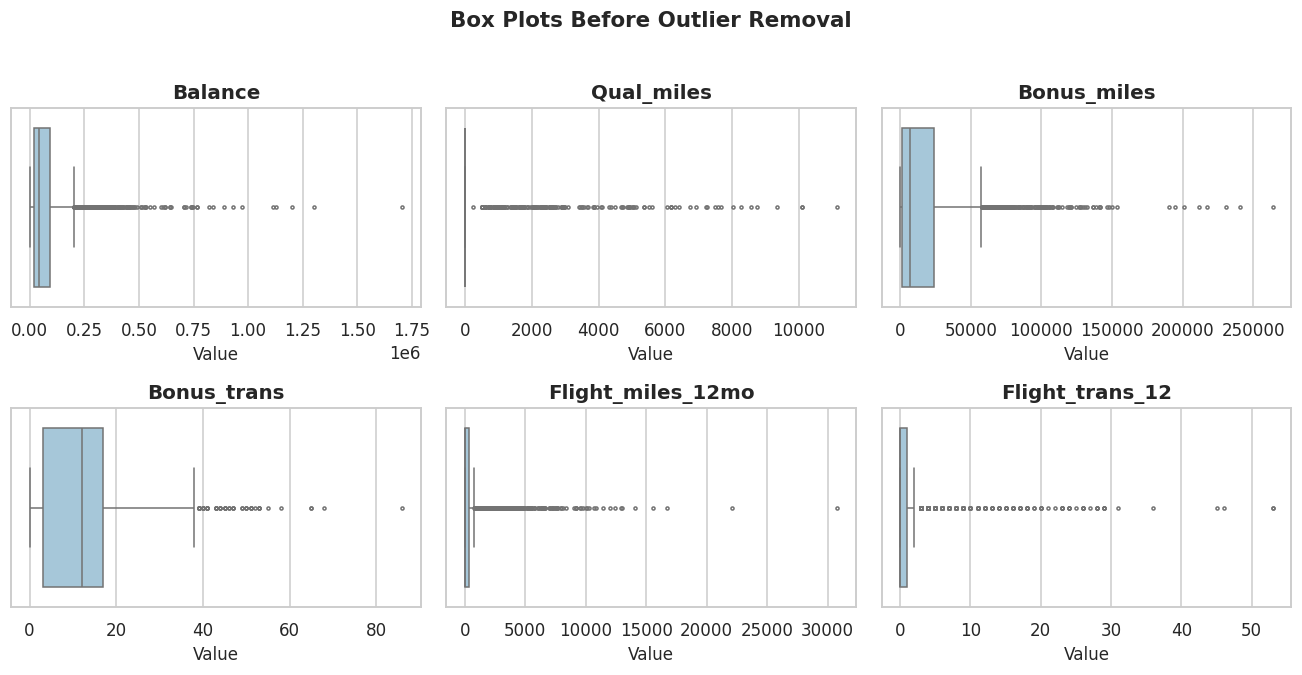

In [4]:
num_cols = ["Balance", "Qual_miles", "Bonus_miles", "Bonus_trans",
            "Flight_miles_12mo", "Flight_trans_12"]
z = ((air[num_cols] - air[num_cols].mean()) / air[num_cols].std()).abs()
keep = (z < 3).all(axis=1)

before = len(air)
clean = air[keep].reset_index(drop=True)
print(f"Rows before: {before}, rows after: {len(clean)}, removed: {before - len(clean)} "
      f"({(before - len(clean)) / before:.1%})")
results["air_rows_before"] = before
results["air_rows_after"] = len(clean)

fig, axes = plt.subplots(2, 3, figsize=(12, 6))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(x=air[c], ax=ax, color="#9ecae1", fliersize=2)
    ax.set_title(c); ax.set_xlabel("Value")
fig.suptitle("Box Plots Before Outlier Removal", fontsize=14, fontweight="bold", y=1.02)
save("cs2_boxplots_before")

### Scaling the features

In [5]:
features = list(clean.columns)
scaler = StandardScaler()
X = scaler.fit_transform(clean[features])
X_df = pd.DataFrame(X, columns=features)
print("Mean after scaling (approx):", X.mean().round(3), " Std:", X.std().round(3))

Mean after scaling (approx): -0.0  Std: 1.0


## 2.3 Exploratory data analysis

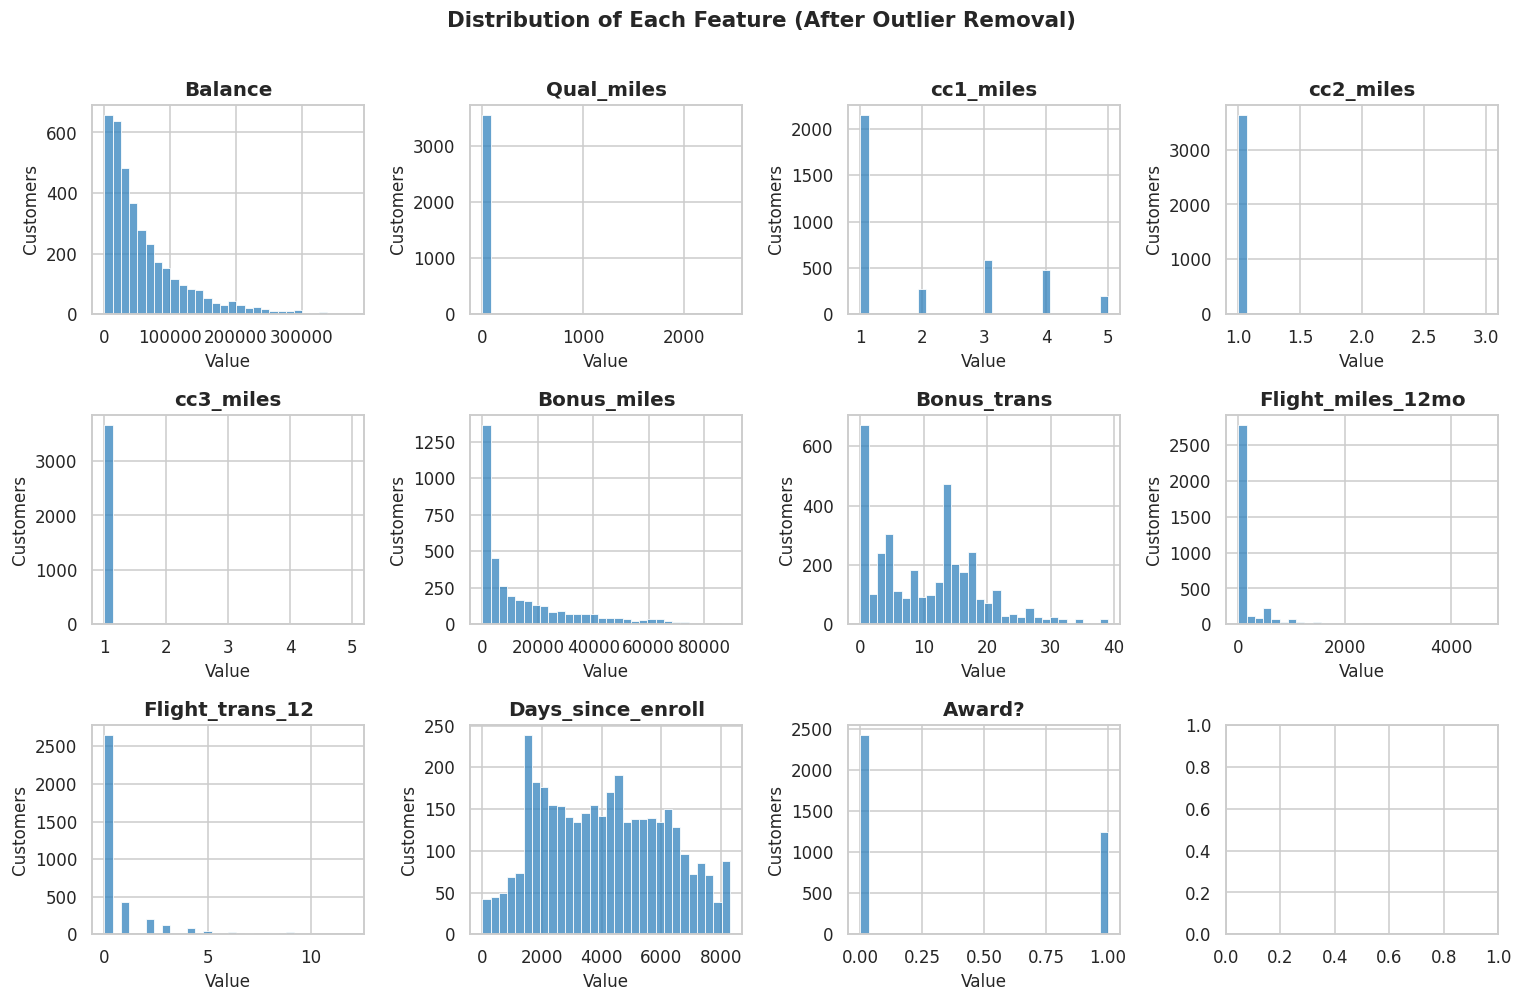

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(14, 9))
for ax, c in zip(axes.ravel(), features):
    sns.histplot(clean[c], bins=30, ax=ax, color="#3182bd")
    ax.set_title(c); ax.set_xlabel("Value"); ax.set_ylabel("Customers")
fig.suptitle("Distribution of Each Feature (After Outlier Removal)", fontsize=14, fontweight="bold", y=1.01)
save("cs2_histograms")

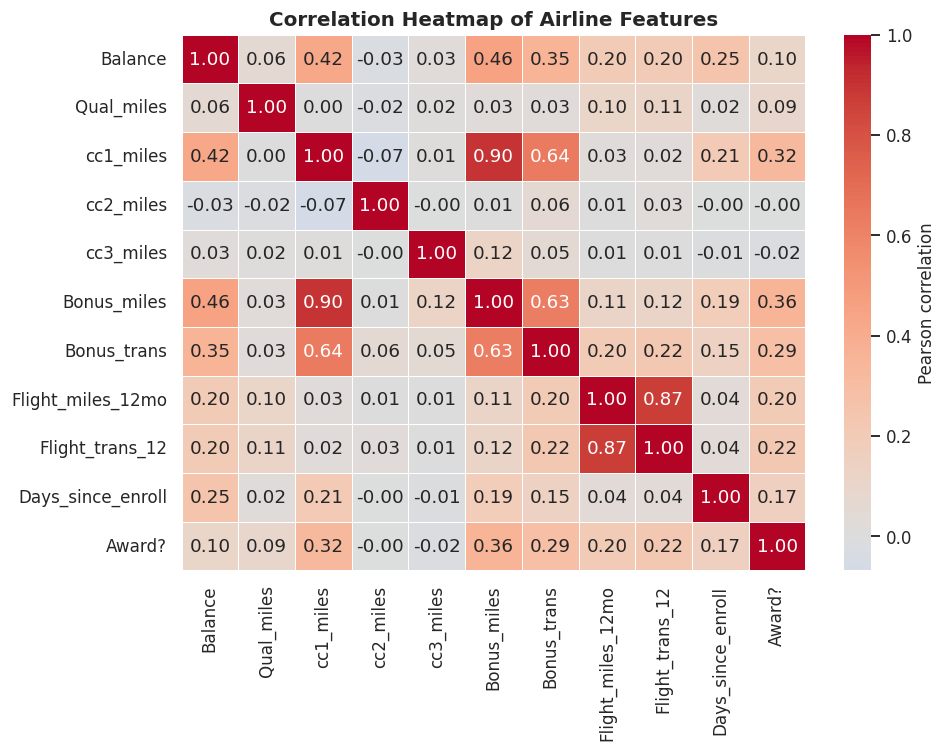

In [7]:
plt.figure(figsize=(9, 7))
sns.heatmap(clean.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Airline Features")
save("cs2_heatmap")

Variance explained by PC1 and PC2: [0.287 0.165] | total: 0.453


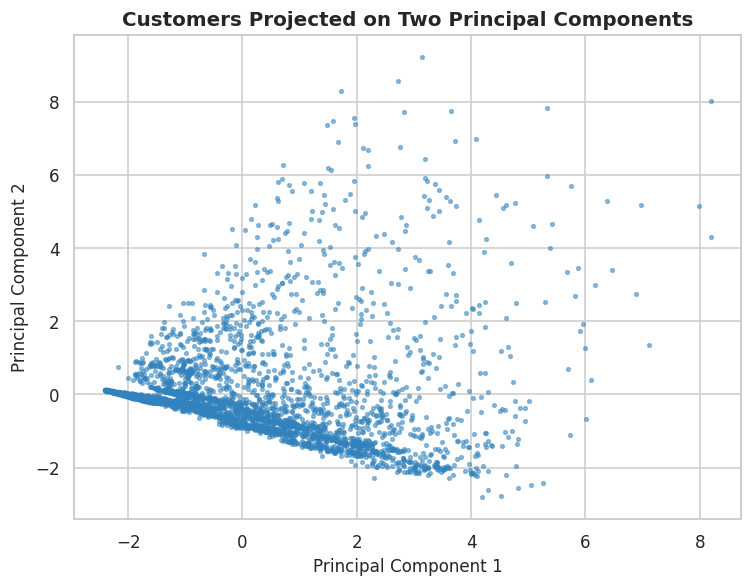

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X)
print("Variance explained by PC1 and PC2:", pca.explained_variance_ratio_.round(3),
      "| total:", pca.explained_variance_ratio_.sum().round(3))
results["pca_var"] = float(pca.explained_variance_ratio_.sum())

plt.figure(figsize=(7, 5.5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=6, alpha=0.5, color="#3182bd")
plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
plt.title("Customers Projected on Two Principal Components")
save("cs2_pca_raw")

## 2.4 K-Means clustering

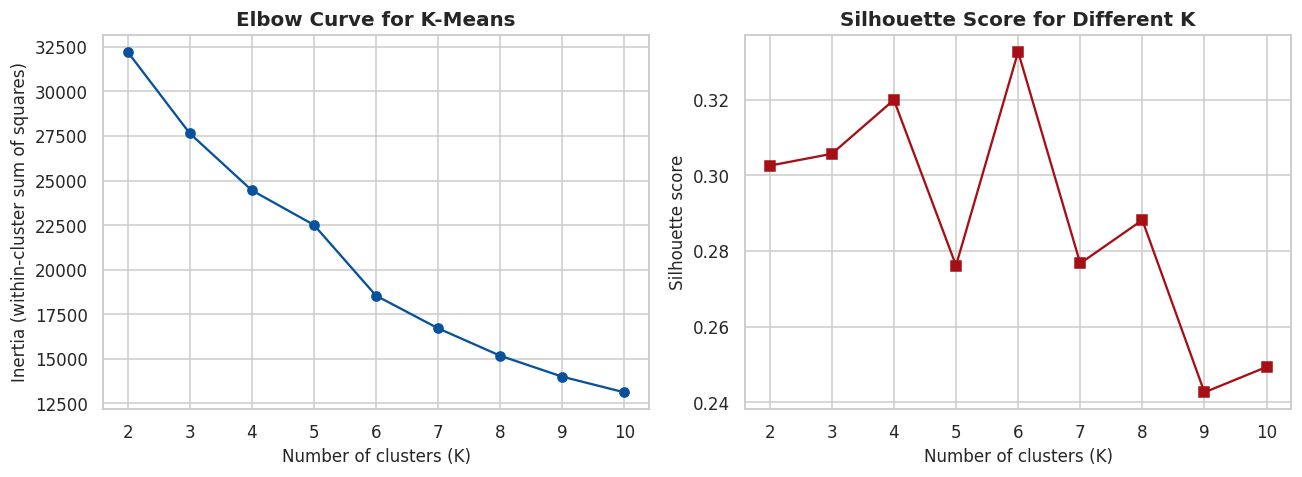

,K,Inertia,Silhouette
0,2,32223.0,0.3026
1,3,27652.0,0.3057
2,4,24453.0,0.3200
3,5,22513.0,0.2762
4,6,18546.0,0.3327
5,7,16712.0,0.2767
6,8,15175.0,0.2882
7,9,13999.0,0.2427
8,10,13122.0,0.2494


In [9]:
k_range = range(2, 11)
inertia, sil = [], []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(list(k_range), inertia, "o-", color="#08519c")
ax[0].set_xlabel("Number of clusters (K)"); ax[0].set_ylabel("Inertia (within-cluster sum of squares)")
ax[0].set_title("Elbow Curve for K-Means")
ax[1].plot(list(k_range), sil, "s-", color="#a50f15")
ax[1].set_xlabel("Number of clusters (K)"); ax[1].set_ylabel("Silhouette score")
ax[1].set_title("Silhouette Score for Different K")
save("cs2_kmeans_elbow")
pd.DataFrame({"K": list(k_range), "Inertia": np.round(inertia, 0), "Silhouette": np.round(sil, 4)})

In [10]:
best_k_sil = int(list(k_range)[int(np.argmax(sil))])
print("K with highest silhouette:", best_k_sil, "->", round(max(sil), 4))
results["km_sil_by_k"] = {int(k): float(s) for k, s in zip(k_range, sil)}

K with highest silhouette: 6 -> 0.3327


In [11]:
K_CHOSEN = 4
kmeans = KMeans(n_clusters=K_CHOSEN, n_init=10, random_state=RANDOM_STATE).fit(X)
clean["KMeans"] = kmeans.labels_
km_sil = silhouette_score(X, kmeans.labels_)
print(f"K-Means (K={K_CHOSEN}) silhouette score: {km_sil:.4f}")
print(clean["KMeans"].value_counts().sort_index().to_string())
results["km_k"] = K_CHOSEN
results["km_sil"] = float(km_sil)
results["km_sizes"] = {int(k): int(v) for k, v in clean["KMeans"].value_counts().sort_index().items()}

profile_km = clean.groupby("KMeans")[features].mean().round(1)
profile_km.insert(0, "Customers", clean["KMeans"].value_counts().sort_index())
profile_km

K-Means (K=4) silhouette score: 0.3200
KMeans
0    2199
1     246
2      38
3    1195


,Customers,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
KMeans,,,,,,,,,,,,
0,2199,37740.5,30.2,1.1,1.0,1.0,3655.9,6.1,97.1,0.3,3676.4,0.2
1,246,97401.5,169.6,2.0,1.0,1.0,19326.5,16.1,2212.4,6.3,4337.1,0.6
2,38,42433.4,0.0,1.1,2.4,1.0,14358.1,14.9,285.3,1.1,3916.6,0.3
3,1195,95421.3,30.7,3.6,1.0,1.0,33194.6,17.4,146.6,0.5,4715.1,0.6


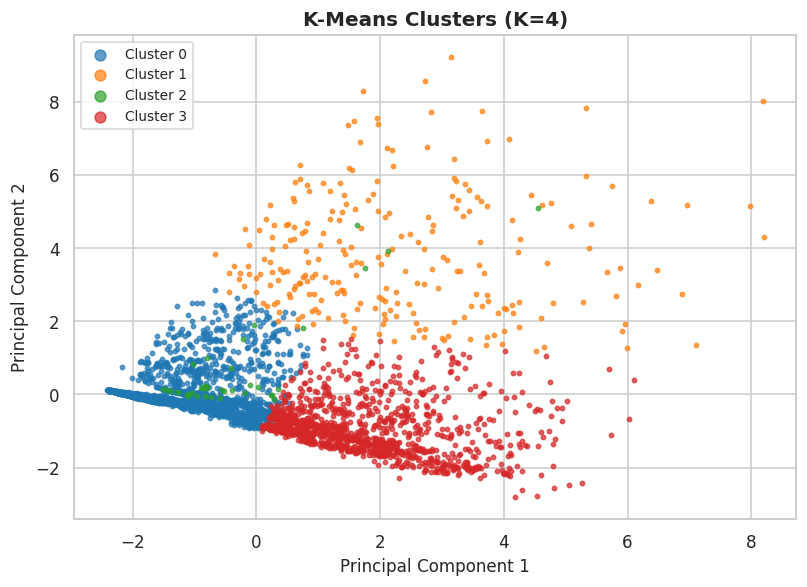

In [12]:
def plot_clusters(labels, title, fname, noise_label=None):
    plt.figure(figsize=(7.5, 5.5))
    palette = sns.color_palette("tab10", n_colors=max(len(set(labels)), 3))
    for i, lab in enumerate(sorted(set(labels))):
        m = labels == lab
        if noise_label is not None and lab == noise_label:
            plt.scatter(X_pca[m, 0], X_pca[m, 1], s=8, c="lightgrey", label="Noise", alpha=0.7)
        else:
            plt.scatter(X_pca[m, 0], X_pca[m, 1], s=8, color=palette[i % 10], label=f"Cluster {lab}", alpha=0.7)
    plt.xlabel("Principal Component 1"); plt.ylabel("Principal Component 2")
    plt.title(title); plt.legend(markerscale=2.5, fontsize=9)
    save(fname)

plot_clusters(kmeans.labels_, f"K-Means Clusters (K={K_CHOSEN})", "cs2_kmeans_clusters")

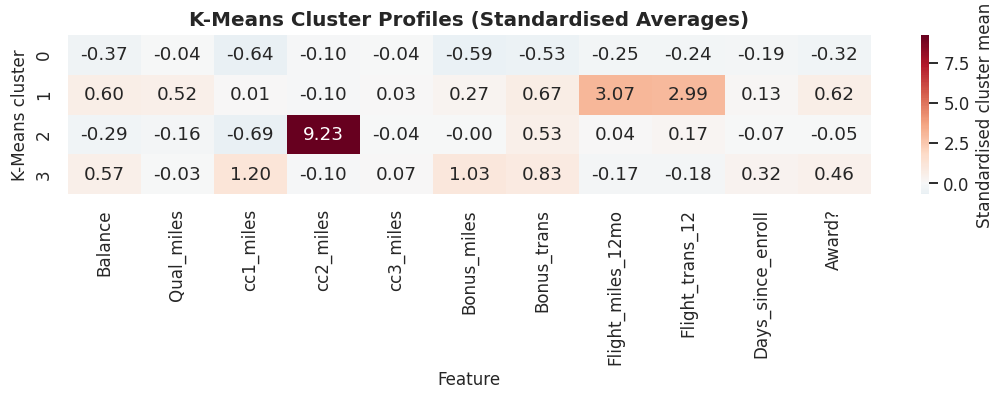

In [13]:
prof_scaled = pd.DataFrame(kmeans.cluster_centers_, columns=features)
plt.figure(figsize=(10, 3.8))
sns.heatmap(prof_scaled, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            cbar_kws={"label": "Standardised cluster mean"})
plt.xlabel("Feature"); plt.ylabel("K-Means cluster")
plt.title("K-Means Cluster Profiles (Standardised Averages)")
save("cs2_kmeans_profile")

## 2.5 Hierarchical clustering

In [14]:
link_scores, link_sizes = {}, {}
for method in ["ward", "complete", "average", "single"]:
    ag = AgglomerativeClustering(n_clusters=4, linkage=method).fit(X)
    link_scores[method] = silhouette_score(X, ag.labels_)
    link_sizes[method] = sorted(np.bincount(ag.labels_).tolist(), reverse=True)
link_df = pd.DataFrame({"Linkage": list(link_scores), "Silhouette": np.round(list(link_scores.values()), 4),
                        "Cluster sizes": [str(v) for v in link_sizes.values()]})
results["hier_link_sizes"] = link_sizes
results["hier_link"] = {k: float(v) for k, v in link_scores.items()}
link_df

,Linkage,Silhouette,Cluster sizes
0,ward,0.2848,"[2355, 1063, 222, 38]"
1,complete,0.6281,"[3634, 38, 3, 3]"
2,average,0.6281,"[3634, 38, 3, 3]"
3,single,0.7886,"[3672, 3, 2, 1]"


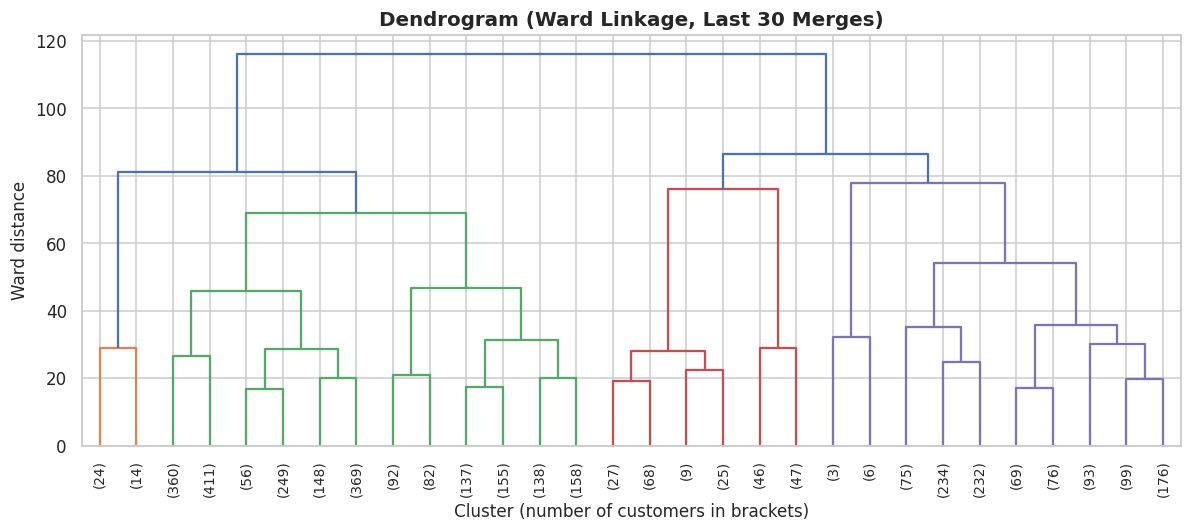

In [15]:
Z = linkage(X, method="ward")
plt.figure(figsize=(11, 5))
dendrogram(Z, truncate_mode="lastp", p=30, show_leaf_counts=True, leaf_rotation=90, leaf_font_size=9,
           color_threshold=0.7 * max(Z[:, 2]))
plt.xlabel("Cluster (number of customers in brackets)"); plt.ylabel("Ward distance")
plt.title("Dendrogram (Ward Linkage, Last 30 Merges)")
save("cs2_dendrogram")

In [16]:
hier = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X)
clean["Hierarchical"] = hier.labels_
hier_sil = silhouette_score(X, hier.labels_)
print(f"Hierarchical (Ward, 4 clusters) silhouette score: {hier_sil:.4f}")
print(clean["Hierarchical"].value_counts().sort_index().to_string())
results["hier_sil"] = float(hier_sil)
results["hier_sizes"] = {int(k): int(v) for k, v in clean["Hierarchical"].value_counts().sort_index().items()}

profile_h = clean.groupby("Hierarchical")[features].mean().round(1)
profile_h.insert(0, "Customers", clean["Hierarchical"].value_counts().sort_index())
profile_h

Hierarchical (Ward, 4 clusters) silhouette score: 0.2848
Hierarchical
0    1063
1    2355
2     222
3      38


,Customers,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
Hierarchical,,,,,,,,,,,,
0,1063,107936.9,3.0,3.6,1.0,1.0,34076.6,16.7,197.8,0.6,4631.9,0.4
1,2355,35797.7,0.2,1.3,1.0,1.0,4887.0,7.3,143.4,0.5,3801.7,0.3
2,222,98828.8,636.0,2.1,1.0,1.0,21300.0,15.3,1734.0,5.1,4095.7,0.6
3,38,42433.4,0.0,1.1,2.4,1.0,14358.1,14.9,285.3,1.1,3916.6,0.3


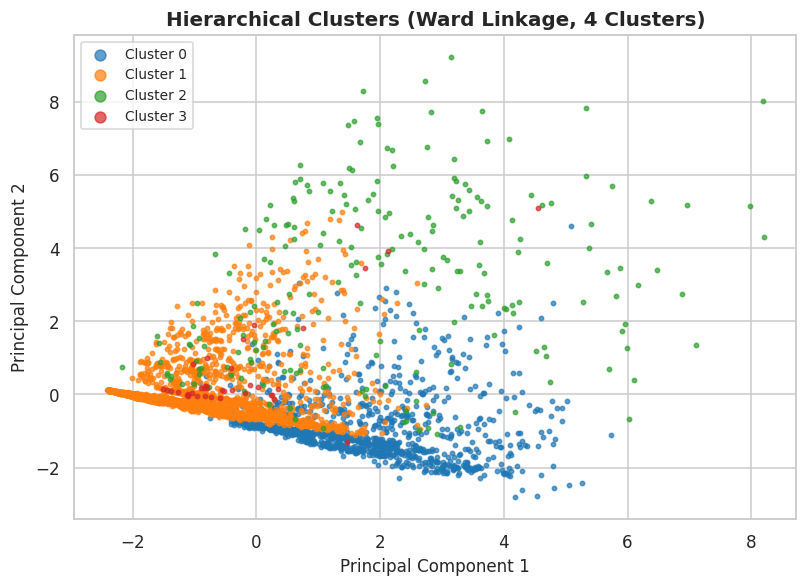

In [17]:
plot_clusters(hier.labels_, "Hierarchical Clusters (Ward Linkage, 4 Clusters)", "cs2_hier_clusters")

## 2.6 DBSCAN

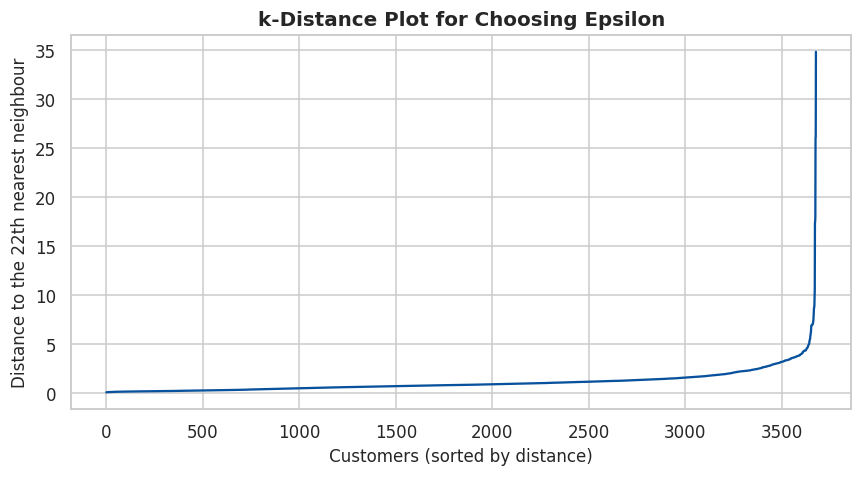

In [18]:
min_pts = 2 * X.shape[1]
nbrs = NearestNeighbors(n_neighbors=min_pts).fit(X)
dist, _ = nbrs.kneighbors(X)
kdist = np.sort(dist[:, -1])

plt.figure(figsize=(8, 4.5))
plt.plot(kdist, color="#08519c")
plt.xlabel("Customers (sorted by distance)"); plt.ylabel(f"Distance to the {min_pts}th nearest neighbour")
plt.title("k-Distance Plot for Choosing Epsilon")
save("cs2_kdistance")

In [19]:
rows = []
for eps in [1.0, 1.5, 2.0, 2.5, 3.0]:
    for mp in [5, 10, 22]:
        lab = DBSCAN(eps=eps, min_samples=mp).fit_predict(X)
        n_clu = len(set(lab)) - (1 if -1 in lab else 0)
        noise = (lab == -1).mean()
        mask = lab != -1
        s = silhouette_score(X[mask], lab[mask]) if n_clu >= 2 else np.nan
        rows.append({"eps": eps, "min_samples": mp, "clusters": n_clu,
                     "noise %": round(100 * noise, 1), "silhouette": round(s, 4) if n_clu >= 2 else np.nan})
db_grid = pd.DataFrame(rows)
db_grid

,eps,min_samples,clusters,noise %,silhouette
0,1.0,5,5,16.3,0.2713
1,1.0,10,2,20.7,0.3017
2,1.0,22,2,27.5,0.3164
3,1.5,5,6,7.4,0.2548
4,1.5,10,3,9.8,0.2763
5,1.5,22,2,12.3,0.2795
6,2.0,5,9,4.0,0.2568
7,2.0,10,3,6.0,0.2658
8,2.0,22,2,8.0,0.2680
9,2.5,5,4,1.6,0.5290


Chosen parameters -> eps: 2.5  min_samples: 10


Clusters found: 4, noise points: 92 (2.5%)
DBSCAN silhouette score (noise excluded): 0.5351
DBSCAN
-1      92
 0    3544
 1      22
 2      10
 3      10


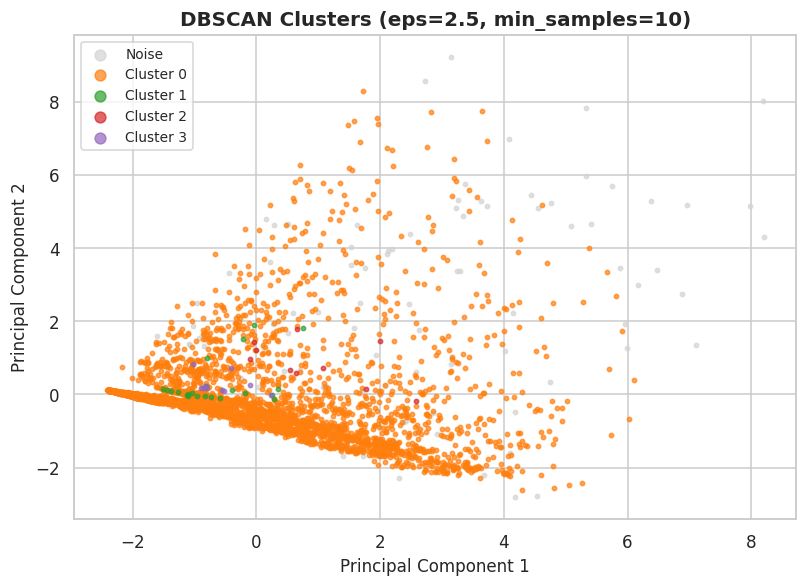

In [20]:
cand = db_grid[(db_grid["clusters"] >= 2) & (db_grid["noise %"] < 15)].dropna()
best = cand.sort_values("silhouette", ascending=False).iloc[0] if len(cand) else \
       db_grid.dropna().sort_values("silhouette", ascending=False).iloc[0]
EPS, MINPTS = float(best["eps"]), int(best["min_samples"])
print("Chosen parameters -> eps:", EPS, " min_samples:", MINPTS)

db = DBSCAN(eps=EPS, min_samples=MINPTS).fit(X)
clean["DBSCAN"] = db.labels_
mask = db.labels_ != -1
n_clusters_db = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
db_sil = silhouette_score(X[mask], db.labels_[mask]) if n_clusters_db >= 2 else float("nan")
print(f"Clusters found: {n_clusters_db}, noise points: {(~mask).sum()} ({(~mask).mean():.1%})")
print(f"DBSCAN silhouette score (noise excluded): {db_sil:.4f}")
print(clean["DBSCAN"].value_counts().sort_index().to_string())
results.update({"db_eps": EPS, "db_minpts": MINPTS, "db_clusters": n_clusters_db,
                "db_noise": int((~mask).sum()), "db_noise_pct": float((~mask).mean() * 100),
                "db_sil": float(db_sil),
                "db_sizes": {int(k): int(v) for k, v in clean["DBSCAN"].value_counts().sort_index().items()}})
plot_clusters(db.labels_, f"DBSCAN Clusters (eps={EPS}, min_samples={MINPTS})", "cs2_dbscan_clusters", noise_label=-1)

In [21]:
profile_db = clean.groupby("DBSCAN")[features].mean().round(1)
profile_db.insert(0, "Customers", clean["DBSCAN"].value_counts().sort_index())
profile_db

,Customers,Balance,Qual_miles,cc1_miles,cc2_miles,cc3_miles,Bonus_miles,Bonus_trans,Flight_miles_12mo,Flight_trans_12,Days_since_enroll,Award?
DBSCAN,,,,,,,,,,,,
-1,92,130398.2,965.8,2.4,1.1,1.2,30775.7,18.0,1388.2,4.1,4365.6,0.6
0,3544,58900.1,9.7,2.0,1.0,1.0,14015.6,10.3,229.3,0.7,4051.4,0.3
1,22,39212.6,0.0,1.0,2.0,1.0,8790.1,13.4,120.5,0.5,3779.2,0.3
2,10,52794.1,2180.2,2.3,1.0,1.0,15716.3,11.1,60.0,0.2,5480.3,0.8
3,10,46401.2,0.0,1.0,3.0,1.0,15355.9,14.7,40.0,0.2,3703.8,0.1


## 2.7 Comparison of the three algorithms

In [22]:
comp = pd.DataFrame({
    "Algorithm": ["K-Means", "Hierarchical (Ward)", "DBSCAN"],
    "Clusters": [K_CHOSEN, 4, n_clusters_db],
    "Silhouette score": [round(km_sil, 4), round(hier_sil, 4), round(db_sil, 4)],
    "Noise points": [0, 0, int((~mask).sum())],
})
results["comparison"] = comp.to_dict(orient="records")
comp

,Algorithm,Clusters,Silhouette score,Noise points
0,K-Means,4,0.3200,0
1,Hierarchical (Ward),4,0.2848,0
2,DBSCAN,4,0.5351,92


In [23]:
from sklearn.metrics import adjusted_rand_score
ari = adjusted_rand_score(clean["KMeans"], clean["Hierarchical"])
print(f"Adjusted Rand Index (K-Means vs Hierarchical): {ari:.3f}")
results["ari_km_hier"] = float(ari)

seg = clean.groupby("KMeans").agg(Customers=("Balance", "size"), Avg_Balance=("Balance", "mean"),
        Avg_Bonus_miles=("Bonus_miles", "mean"), Avg_Flight_miles=("Flight_miles_12mo", "mean"),
        Avg_Days_enrolled=("Days_since_enroll", "mean"), Award_rate=("Award?", "mean")).round(2)
seg

Adjusted Rand Index (K-Means vs Hierarchical): 0.556


,Customers,Avg_Balance,Avg_Bonus_miles,Avg_Flight_miles,Avg_Days_enrolled,Award_rate
KMeans,,,,,,
0,2199,37740.52,3655.86,97.11,3676.42,0.19
1,246,97401.51,19326.52,2212.45,4337.13,0.63
2,38,42433.42,14358.08,285.26,3916.63,0.32
3,1195,95421.26,33194.56,146.60,4715.12,0.56


In [24]:
results["km_profile"] = clean.groupby("KMeans")[features].mean().round(2).to_dict(orient="index")
results["km_profile"] = {str(k): v for k, v in results["km_profile"].items()}
results["hier_profile"] = {str(k): v for k, v in clean.groupby("Hierarchical")[features].mean().round(2).to_dict(orient="index").items()}
results["db_profile"] = {str(k): v for k, v in clean.groupby("DBSCAN")[features].mean().round(2).to_dict(orient="index").items()}
results["db_grid"] = db_grid.fillna(-1).to_dict(orient="records")

# Case Study 5: Wine Quality Assessment

## 5.1 Loading the data

In [25]:
red = pd.read_csv(DATA / "winequality-red.csv", sep=";")
white = pd.read_csv(DATA / "winequality-white.csv", sep=";")
red["wine_type"] = "red"; white["wine_type"] = "white"
wine = pd.concat([red, white], ignore_index=True)

predictors = ["fixed acidity", "volatile acidity", "citric acid", "residual sugar", "chlorides",
              "free sulfur dioxide", "total sulfur dioxide", "density", "pH", "sulphates", "alcohol"]
print("Red:", red.shape, " White:", white.shape, " Combined:", wine.shape)
print("Missing values:", int(wine[predictors + ['quality']].isna().sum().sum()))
results["wine_n"] = len(wine); results["wine_red_n"] = len(red); results["wine_white_n"] = len(white)
wine.head()

Red: (1599, 13)  White: (4898, 13)  Combined: (6497, 13)
Missing values: 0


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,wine_type
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,red
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,red
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,red
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,red


## Task 1: Statistical analysis

### 1(a) Descriptive statistics

In [26]:
cols3 = ["alcohol", "volatile acidity", "residual sugar"]
desc = pd.DataFrame({
    "Mean": wine[cols3].mean(),
    "Median": wine[cols3].median(),
    "Mode": [wine[c].mode().iloc[0] for c in cols3],
    "Std Dev": wine[cols3].std(),
    "Skewness": wine[cols3].skew(),
}).round(4)
results["desc"] = desc.to_dict(orient="index")
desc

,Mean,Median,Mode,Std Dev,Skewness
alcohol,10.4918,10.30,9.50,1.1927,0.5657
volatile acidity,0.3397,0.29,0.28,0.1646,1.4951
residual sugar,5.4432,3.00,2.00,4.7578,1.4354


### 1(b) Relative variability (Coefficient of Variation)

In [27]:
cv = (wine[cols3].std() / wine[cols3].mean() * 100).round(2)
results["cv"] = cv.to_dict()
print("Coefficient of variation (%):"); print(cv.to_string())
print("\nMost variable attribute:", cv.idxmax())

Coefficient of variation (%):
alcohol             11.37
volatile acidity    48.47
residual sugar      87.41

Most variable attribute: residual sugar


### 1(c) Pearson correlation between alcohol and quality

In [28]:
r, p = stats.pearsonr(wine["alcohol"], wine["quality"])
print(f"Pearson r = {r:.4f}, p-value = {p:.3e}")
results["r_alc_q"] = float(r); results["p_alc_q"] = float(p)

Pearson r = 0.4443, p-value = 1.498e-312


## Task 2: Exploratory data analysis

### 2(a) Histogram of quality scores

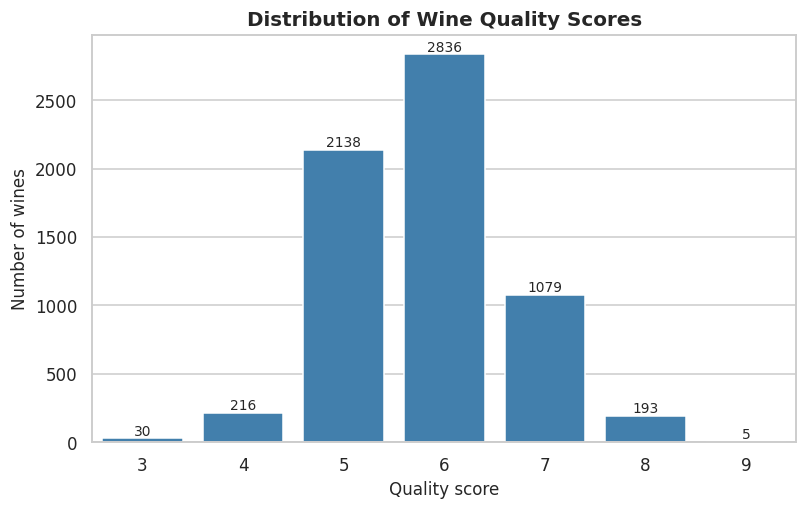

quality
3     0.5
4     3.3
5    32.9
6    43.7
7    16.6
8     3.0
9     0.1


In [29]:
plt.figure(figsize=(7.5, 4.8))
ax = sns.countplot(x="quality", data=wine, color="#3182bd")
for c in ax.containers: ax.bar_label(c, fontsize=9)
plt.xlabel("Quality score"); plt.ylabel("Number of wines")
plt.title("Distribution of Wine Quality Scores")
save("cs5_quality_hist")
qc = wine["quality"].value_counts().sort_index()
results["quality_counts"] = {int(k): int(v) for k, v in qc.items()}
results["quality_mean"] = float(wine["quality"].mean()); results["quality_std"] = float(wine["quality"].std())
print((qc / len(wine) * 100).round(1).to_string())

### 2(b) Box plot of alcohol by quality

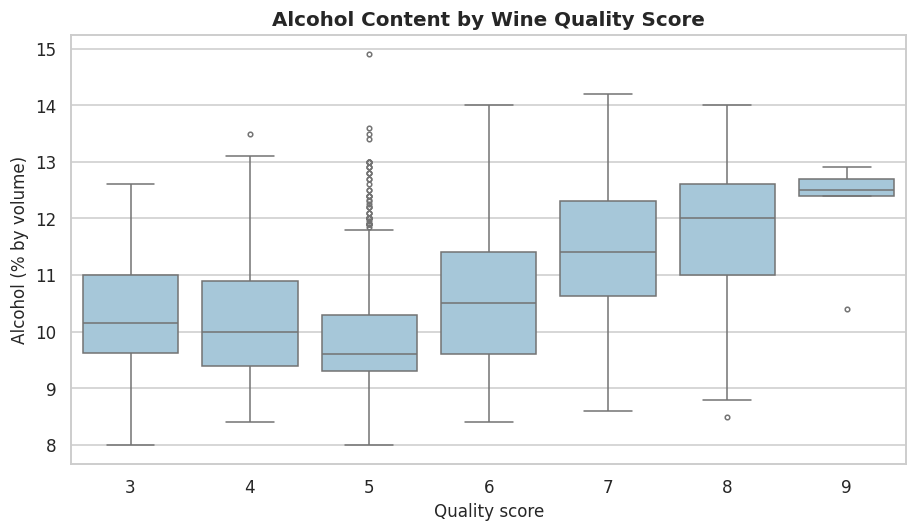

quality
3    10.15
4    10.00
5     9.60
6    10.50
7    11.40
8    12.00
9    12.50


In [30]:
plt.figure(figsize=(8.5, 5))
sns.boxplot(x="quality", y="alcohol", data=wine, color="#9ecae1", fliersize=3)
plt.xlabel("Quality score"); plt.ylabel("Alcohol (% by volume)")
plt.title("Alcohol Content by Wine Quality Score")
save("cs5_alcohol_box")
med = wine.groupby("quality")["alcohol"].median().round(2)
results["alc_median_by_q"] = {int(k): float(v) for k, v in med.items()}
print(med.to_string())

### 2(c) Correlation heatmap

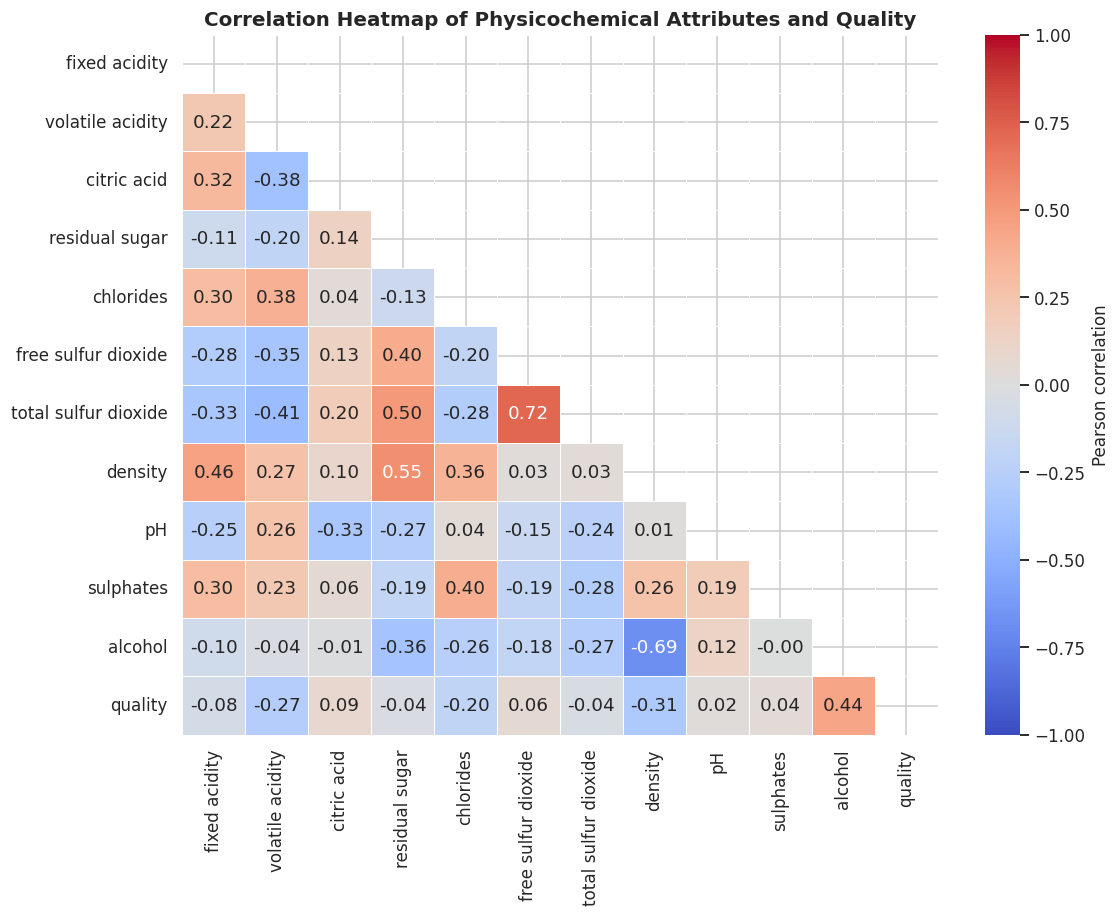

In [31]:
corr = wine[predictors + ["quality"]].corr()
plt.figure(figsize=(10.5, 8.5))
mask_up = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask_up, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            linewidths=0.5, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap of Physicochemical Attributes and Quality")
save("cs5_heatmap")
results["corr_with_quality"] = corr["quality"].drop("quality").round(4).to_dict()

### 2(d) Two attributes most related to quality

In [32]:
cq = corr["quality"].drop("quality")
top2 = cq.abs().sort_values(ascending=False).head(2).index.tolist()
print(cq.round(4).sort_values(key=abs, ascending=False).to_string())
print("\nTop two by |r|:", top2)
results["top2_corr"] = {a: float(cq[a]) for a in top2}

alcohol                 0.4443
density                -0.3059
volatile acidity       -0.2657
chlorides              -0.2007
citric acid             0.0855
fixed acidity          -0.0767
free sulfur dioxide     0.0555
total sulfur dioxide   -0.0414
sulphates               0.0385
residual sugar         -0.0370
pH                      0.0195

Top two by |r|: ['alcohol', 'density']


## Task 3: Predictive modelling

### 3(a, b) Train-test split and model fitting

In [33]:
X_w = wine[predictors]
y_w = wine["quality"]
X_train, X_test, y_train, y_test = train_test_split(X_w, y_w, test_size=0.2, random_state=RANDOM_STATE)
print("Training:", X_train.shape, " Testing:", X_test.shape)

lr = LinearRegression().fit(X_train, y_train)
y_pred = lr.predict(X_test)
print("Intercept:", round(lr.intercept_, 3))
pd.DataFrame({"Attribute": predictors, "Coefficient": lr.coef_.round(4)})

Training: (5197, 11)  Testing: (1300, 11)
Intercept: 59.42


,Attribute,Coefficient
0,fixed acidity,0.0790
1,volatile acidity,-1.3508
2,citric acid,-0.1438
3,residual sugar,0.0459
4,chlorides,-0.3328
5,free sulfur dioxide,0.0070
6,total sulfur dioxide,-0.0027
7,density,-58.9451
8,pH,0.4828
9,sulphates,0.8084


### 3(c) Test-set performance

In [34]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)
print(f"MAE  : {mae:.4f}")
print(f"MSE  : {mse:.4f}")
print(f"RMSE : {rmse:.4f}")
print(f"R2   : {r2:.4f}")
results["metrics"] = {"MAE": float(mae), "MSE": float(mse), "RMSE": float(rmse), "R2": float(r2)}
results["train_r2"] = float(lr.score(X_train, y_train))
base = np.full(len(y_test), y_train.mean())
results["baseline_rmse"] = float(np.sqrt(mean_squared_error(y_test, base)))
print("Baseline RMSE (predict the mean):", round(results["baseline_rmse"], 4))
print("Within +/-0.5 of actual after rounding:", f"{(np.round(y_pred) == y_test).mean():.1%}",
      "| within +/-1:", f"{(np.abs(np.round(y_pred) - y_test) <= 1).mean():.1%}")
results["exact_acc"] = float((np.round(y_pred) == y_test).mean())
results["within1_acc"] = float((np.abs(np.round(y_pred) - y_test) <= 1).mean())

MAE  : 0.5659
MSE  : 0.5467
RMSE : 0.7394
R2   : 0.2598
Baseline RMSE (predict the mean): 0.8596
Within +/-0.5 of actual after rounding: 53.9% | within +/-1: 94.8%


### 3(d) Most influential predictors and multicollinearity

alcohol                 0.3678
residual sugar          0.2514
volatile acidity       -0.2499
density                -0.2023
total sulfur dioxide   -0.1706
free sulfur dioxide     0.1398
sulphates               0.1371
fixed acidity           0.1161
pH                      0.0879
citric acid            -0.0237
chlorides              -0.0132


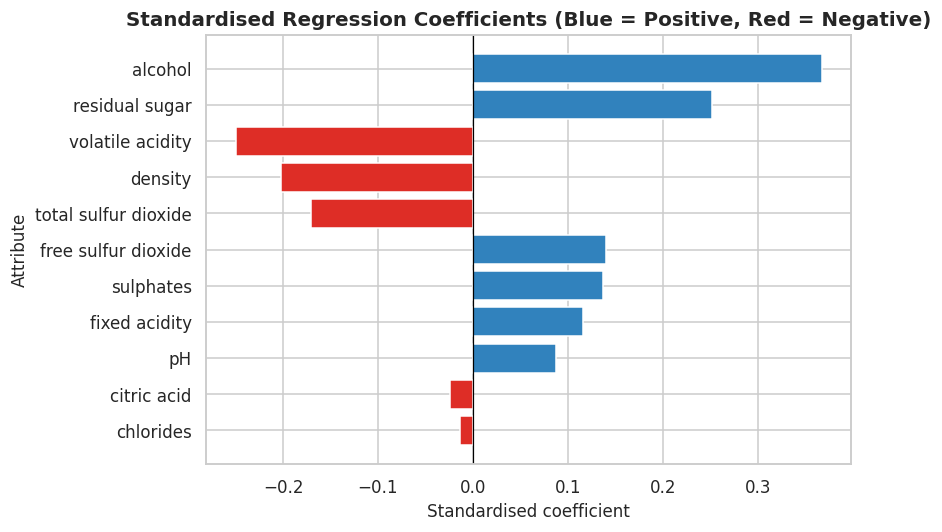

In [35]:
sx, sy = StandardScaler(), StandardScaler()
Xs = sx.fit_transform(X_train)
ys = sy.fit_transform(y_train.values.reshape(-1, 1)).ravel()
lr_std = LinearRegression().fit(Xs, ys)
std_coef = pd.Series(lr_std.coef_, index=predictors)
order = std_coef.abs().sort_values(ascending=False).index
print(std_coef[order].round(4).to_string())
results["std_coef"] = std_coef[order].round(4).to_dict()

plt.figure(figsize=(8, 5))
colors = ["#3182bd" if v > 0 else "#de2d26" for v in std_coef[order][::-1]]
plt.barh(order[::-1], std_coef[order][::-1], color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Standardised coefficient"); plt.ylabel("Attribute")
plt.title("Standardised Regression Coefficients (Blue = Positive, Red = Negative)")
save("cs5_std_coef")

density                 15.51
residual sugar           7.20
fixed acidity            4.74
alcohol                  4.62
total sulfur dioxide     2.96
pH                       2.47
free sulfur dioxide      2.16
volatile acidity         1.94
chlorides                1.65
citric acid              1.61
sulphates                1.54


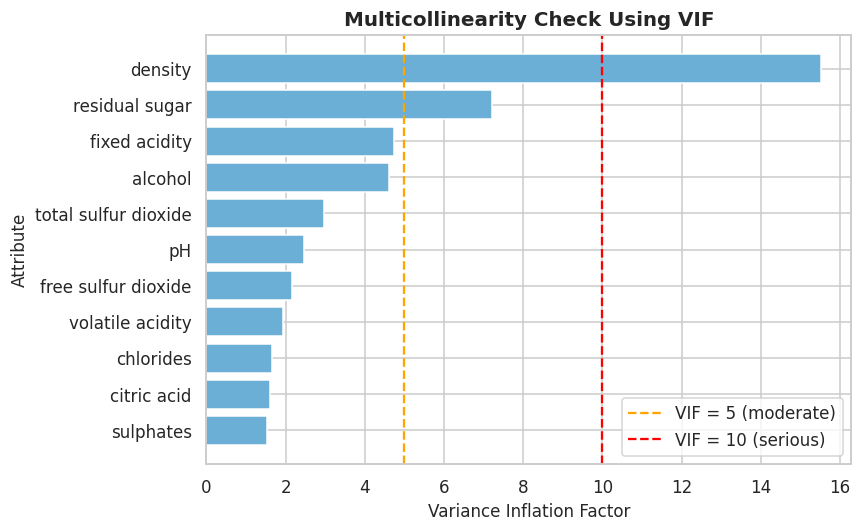

In [36]:
def vif_table(df):
    out = {}
    for c in df.columns:
        others = df.drop(columns=c)
        r2_j = LinearRegression().fit(others, df[c]).score(others, df[c])
        out[c] = 1 / (1 - r2_j)
    return pd.Series(out).sort_values(ascending=False)

vif = vif_table(X_train).round(2)
results["vif"] = vif.to_dict()
print(vif.to_string())

plt.figure(figsize=(8, 5))
plt.barh(vif.index[::-1], vif.values[::-1], color="#6baed6")
plt.axvline(5, color="orange", ls="--", label="VIF = 5 (moderate)")
plt.axvline(10, color="red", ls="--", label="VIF = 10 (serious)")
plt.xlabel("Variance Inflation Factor"); plt.ylabel("Attribute")
plt.title("Multicollinearity Check Using VIF")
plt.legend()
save("cs5_vif")

In [37]:
pred_nd = [p for p in predictors if p != "density"]
sx2 = StandardScaler(); sy2 = StandardScaler()
lr_nd = LinearRegression().fit(sx2.fit_transform(X_train[pred_nd]), ys)
std_nd = pd.Series(lr_nd.coef_, index=pred_nd)
Xte_nd = X_test[pred_nd]
lr_nd_raw = LinearRegression().fit(X_train[pred_nd], y_train)
r2_nd = r2_score(y_test, lr_nd_raw.predict(Xte_nd))
print("Standardised coefficients without density:")
print(std_nd.reindex(std_nd.abs().sort_values(ascending=False).index).round(4).to_string())
print(f"\nTest R2 without density: {r2_nd:.4f}  (with density: {r2:.4f})")
results["std_coef_no_density"] = std_nd.reindex(std_nd.abs().sort_values(ascending=False).index).round(4).to_dict()
results["r2_no_density"] = float(r2_nd)
results["vif_no_density"] = vif_table(X_train[pred_nd]).round(2).to_dict()

Standardised coefficients without density:
alcohol                 0.4597
volatile acidity       -0.2749
total sulfur dioxide   -0.1545
free sulfur dioxide     0.1401
residual sugar          0.1289
sulphates               0.1151
pH                      0.0349
fixed acidity           0.0278
chlorides              -0.0271
citric acid            -0.0244

Test R2 without density: 0.2593  (with density: 0.2598)


### 3(e) Predicted versus actual quality

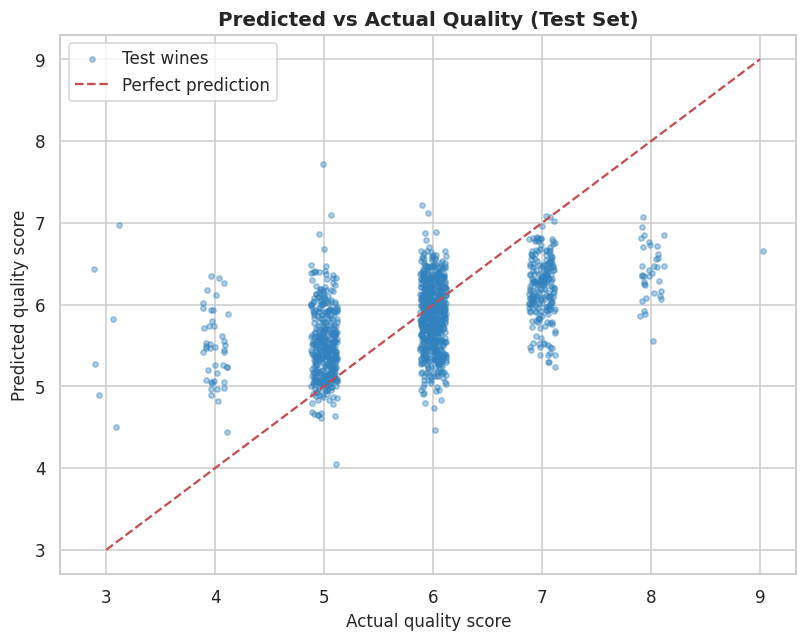

Predicted range: 4.05 to 7.72
actual
3    5.65
4    5.48
5    5.51
6    5.86
7    6.20
8    6.39
9    6.65


In [38]:
rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.uniform(-0.12, 0.12, len(y_test))
plt.figure(figsize=(7.5, 6))
plt.scatter(y_test + jitter, y_pred, s=12, alpha=0.4, color="#3182bd", label="Test wines")
plt.plot([3, 9], [3, 9], "r--", label="Perfect prediction")
plt.xlabel("Actual quality score"); plt.ylabel("Predicted quality score")
plt.title("Predicted vs Actual Quality (Test Set)")
plt.legend()
save("cs5_pred_vs_actual")

print("Predicted range:", y_pred.min().round(2), "to", y_pred.max().round(2))
print(pd.DataFrame({"actual": y_test.values, "pred": y_pred}).groupby("actual")["pred"].mean().round(2).to_string())

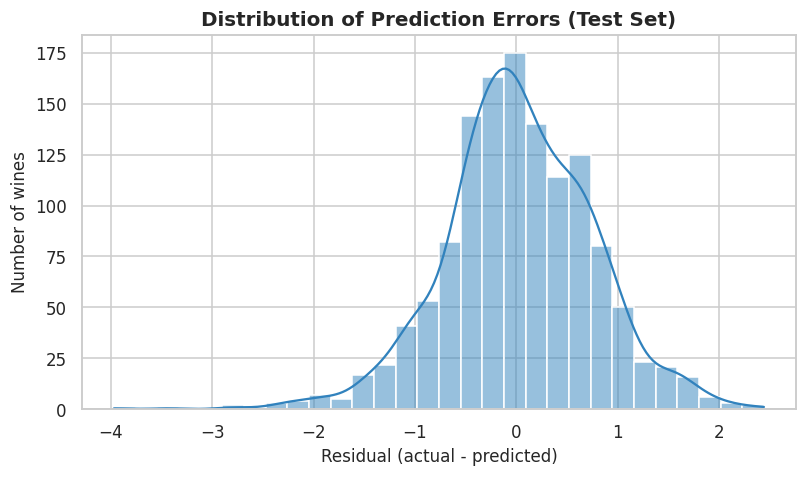

In [39]:
residuals = y_test - y_pred
plt.figure(figsize=(7.5, 4.5))
sns.histplot(residuals, bins=30, kde=True, color="#3182bd")
plt.xlabel("Residual (actual - predicted)"); plt.ylabel("Number of wines")
plt.title("Distribution of Prediction Errors (Test Set)")
save("cs5_residuals")

## Task 4: Business decision-making

In [40]:
print("Test R2:", round(r2, 3), "| RMSE:", round(rmse, 3), "| MAE:", round(mae, 3))
print(f"Only {results['exact_acc']:.0%} of wines get the exact score right; {results['within1_acc']:.0%} are within one point.")

Test R2: 0.26 | RMSE: 0.739 | MAE: 0.566
Only 54% of wines get the exact score right; 95% are within one point.


In [41]:
with open(RES / "summary.json", "w") as f:
    json.dump(results, f, indent=2, default=float)
print("Saved results/summary.json")

Saved results/summary.json
